# E-Commerce Landing Page A/B Testing

## 1. Problem Statement

An e-commerce company is testing a new landing page against its existing
landing page.

Users are divided into two groups:

- **Control** → Existing landing page
- **Treatment** → New landing page

The primary outcome is whether a user converts (`converted = 1`) or does not
convert (`converted = 0`).

### Main Question

> Does the new landing page produce a statistically significant and practically
> meaningful improvement in customer conversion compared with the existing
> landing page?

The analysis will compare the Treatment and Control groups using exploratory
data analysis, statistical hypothesis testing, confidence intervals, and
regression-based analysis.


## 2. Business Objective

The objective is to determine whether the new landing page should be
considered for further rollout based on its effect on customer conversion.

The analysis focuses on:

1. Comparing conversion rates between Control and Treatment.
2. Measuring the size of the treatment effect.
3. Determining whether the observed difference is statistically significant.
4. Estimating the uncertainty around the treatment effect.
5. Checking whether the treatment effect differs across user segments.
6. Evaluating the treatment effect after adjusting for other observed
   characteristics.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math as m
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv("AB Testing Data.csv")

In [3]:
df.head()

,user_id,timestamp,group,landing_page,converted,age,gender,location,session_duration,pages_visited,device_type,purchase_amount
0,U1,2025-08-02 15:27:54.137058,control,old_page,0,37,Male,Pakistan,3.69,4,Mobile,0.0
1,U2,2024-04-22 10:22:51.712050,treatment,new_page,0,31,Female,UK,1.29,3,Desktop,0.0
2,U3,2024-08-14 21:35:11.135894,treatment,new_page,0,38,Male,US,3.72,5,Desktop,0.0
3,U4,2025-03-19 03:28:51.120807,treatment,new_page,0,28,Female,India,7.76,2,Mobile,0.0
4,U5,2024-12-22 13:13:17.973162,control,old_page,0,33,Male,Australia,6.78,6,Mobile,0.0


## 3. Dataset Understanding

The dataset contains user-level information from an A/B testing experiment.

### Key Variables

| Variable | Description |
|---|---|
| `user_id` | Unique identifier for each user |
| `timestamp` | Time associated with the user activity |
| `group` | Experiment group: Control or Treatment |
| `landing_page` | Landing page shown to the user |
| `converted` | Whether the user completed the desired action |
| `age` | User age |
| `gender` | User gender |
| `location` | User location |
| `session_duration` | Duration of the user's session |
| `pages_visited` | Number of pages visited |
| `device_type` | Device used by the user |
| `purchase_amount` | Purchase amount associated with the user |

### Primary Variables for the Experiment

The main variables used to evaluate the experiment are:

- `group` → Treatment vs Control
- `converted` → Primary outcome
- `landing_page` → Version of the landing page shown

In [4]:
print("Columns_Name: ", df.columns)


print("\nShpe:", df.shape)

Columns_Name:  Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted', 'age',
       'gender', 'location', 'session_duration', 'pages_visited',
       'device_type', 'purchase_amount'],
      dtype='object')

Shpe: (294478, 12)


## 4. Experiment Audit

Before performing statistical analysis, we need to check whether the dataset
has the basic structure expected from an A/B experiment.

We will verify:

- Dataset size
- Unique users
- Missing values
- Duplicate records
- Control/Treatment distribution
- Landing-page assignment
- Outcome distribution
- Basic categorical distributions

In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Unique users:", df["user_id"].nunique())

Rows: 294478
Columns: 12
Unique users: 294478


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df.isnull().sum()

user_id             0
timestamp           0
group               0
landing_page        0
converted           0
age                 0
gender              0
location            0
session_duration    0
pages_visited       0
device_type         0
purchase_amount     0
dtype: int64

In [8]:
df["group"].value_counts(normalize=True).mul(100).round(2)

group
treatment    50.11
control      49.89
Name: proportion, dtype: float64

In [9]:
df.landing_page.value_counts(normalize=True)*100

landing_page
new_page    50.10629
old_page    49.89371
Name: proportion, dtype: float64

In [10]:
df["converted"].value_counts(normalize=True).mul(100).round(2)

converted
0    85.08
1    14.92
Name: proportion, dtype: float64

### Conversion Outcome

The `converted` variable represents whether the user completed the desired
action.

- `converted = 1` → User converted
- `converted = 0` → User did not convert

## 5. Data Cleaning

The dataset was checked for missing values, duplicate records, and basic
structural inconsistencies.

The following checks were performed:

- Missing-value check
- Duplicate-record check
- Unique-user check
- Data-type inspection
- Category consistency
- Experiment-group and landing-page consistency

No missing values or duplicate user records were identified in the dataset.

No observations are removed solely because they appear as statistical
outliers. Extreme but plausible values can represent genuine user behavior
and should not automatically be treated as errors.

## 6. Exploratory Data Analysis

Exploratory Data Analysis is used to understand the distribution of the
variables and identify patterns before performing statistical inference.

The analysis is divided into:

1. Univariate Analysis
2. Bivariate Analysis

### 6.1 Univariate Analysis

Univariate analysis examines one variable at a time.

For numerical variables, we examine distributions using histograms and
box plots.

For categorical variables, we examine category frequencies using bar charts.

### Numerical Variables

We examine the distributions of the numerical variables using histograms and
box plots.

The numerical variables are:

- `age`
- `session_duration`
- `pages_visited`
- `purchase_amount`

These plots help us understand the distribution, central tendency, spread,
skewness, and potential extreme values in the data.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   user_id           294478 non-null  object 
 1   timestamp         294478 non-null  object 
 2   group             294478 non-null  object 
 3   landing_page      294478 non-null  object 
 4   converted         294478 non-null  int64  
 5   age               294478 non-null  int64  
 6   gender            294478 non-null  object 
 7   location          294478 non-null  object 
 8   session_duration  294478 non-null  float64
 9   pages_visited     294478 non-null  int64  
 10  device_type       294478 non-null  object 
 11  purchase_amount   294478 non-null  float64
dtypes: float64(2), int64(3), object(7)
memory usage: 27.0+ MB


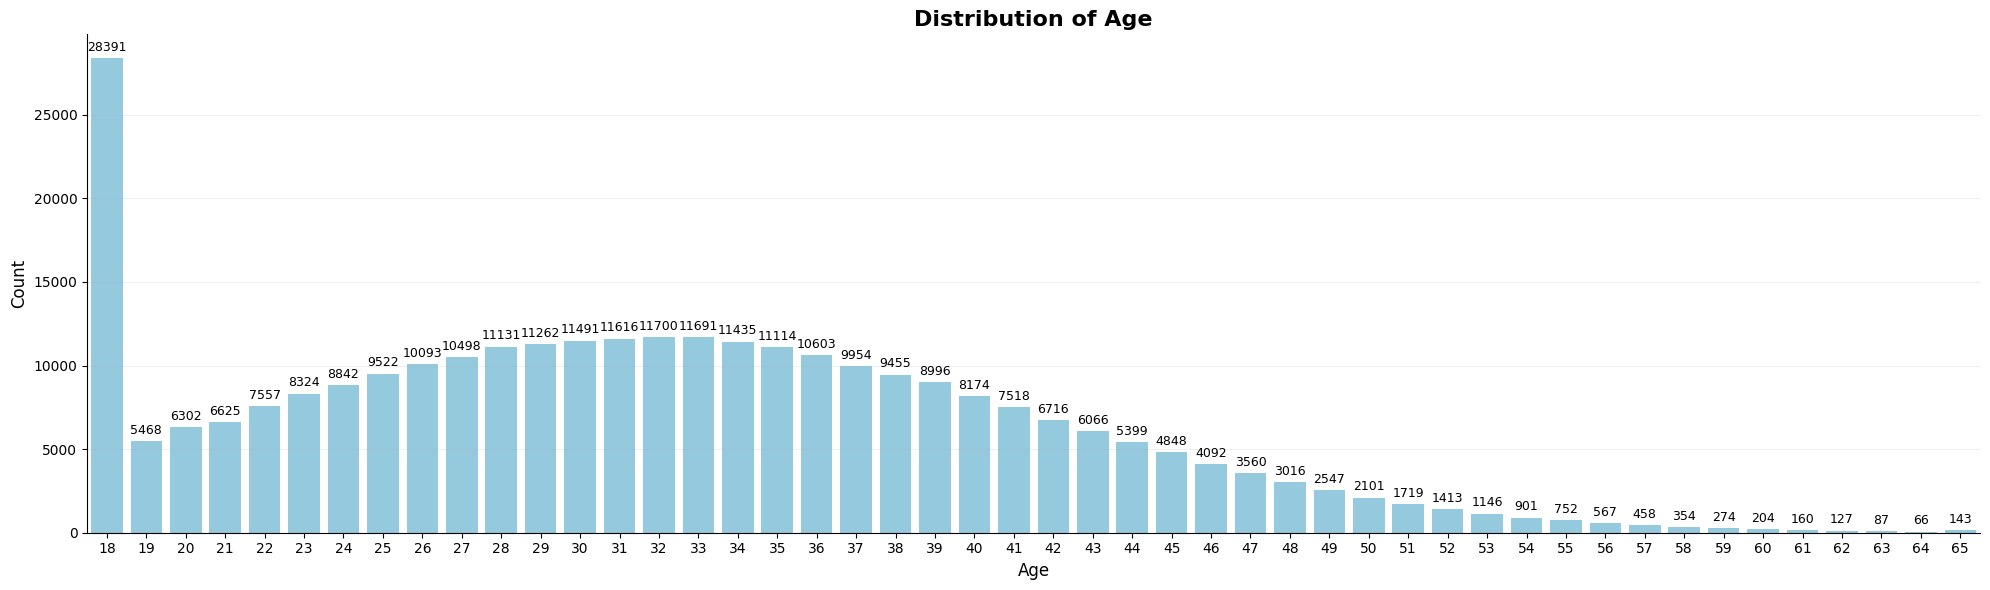

In [12]:
plt.figure(figsize=(20, 6))
ax = (sns.countplot(x=df['age'], color = 'skyblue'))
plt.title("Distribution of Age", fontsize=16, fontweight="bold")
plt.xlabel("Age", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for i in ax.containers:
    ax.bar_label(i, fmt="%d", padding=3, fontsize = 9)


plt.tight_layout()
plt.show()

#### Age

The age distribution is right-skewed, with most users concentrated around the
late 20s to mid-30s.

The box plot shows some higher-age observations, but these values are within a
plausible human age range and are therefore not automatically treated as
errors.

Age is right-skewed, with most users concentrated around the late 20s to mid-30s. The median age is approximately 32–33 years. The box plot identifies several higher-age observations (approximately 58–65) as potential outliers, but these values are plausible and should not be removed without evidence that they are erroneous.

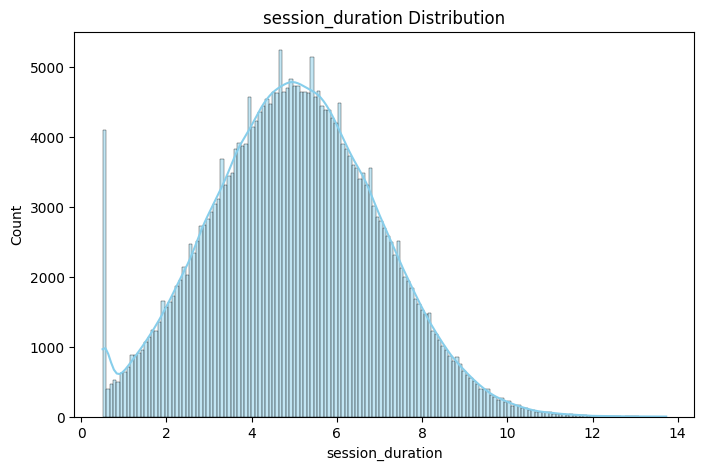

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df['session_duration'], color="skyblue", kde=True)
plt.title("session_duration Distribution")
plt.xlabel("session_duration")
plt.ylabel("Count")
plt.show()

#### Session Duration

Session duration is right-skewed, with most sessions concentrated around the
lower-to-middle range.

The distribution also contains some longer sessions. These observations may
represent genuine user behavior and are not automatically removed as outliers.

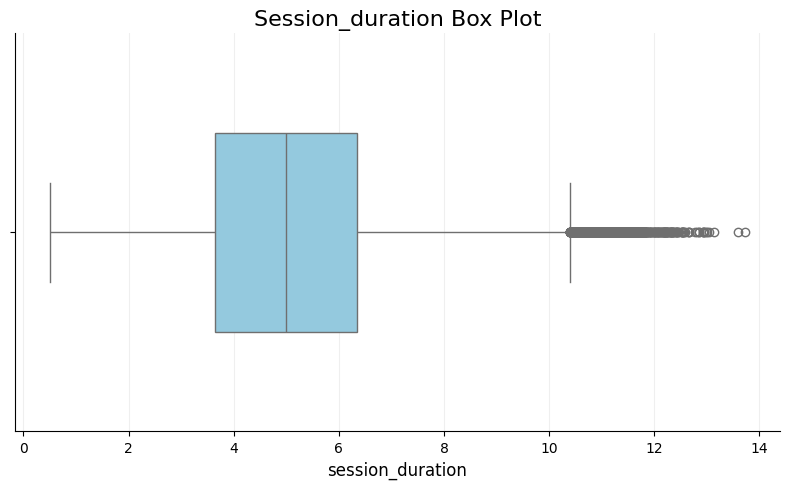

In [14]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['session_duration'], color="skyblue", width=0.5)
plt.title("Session_duration Box Plot", fontsize=16, fontweight=0.5)
plt.xlabel("session_duration", fontsize=12)
plt.grid(axis='x', alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

Session duration is positively skewed, with a median of ~4.99 units. The middle 50% of sessions fall roughly between 3.7 and 6.3 units. Several higher-duration observations beyond approximately 10.5 are flagged as potential outliers, producing a long right tail. These observations should be investigated rather than automatically removed.

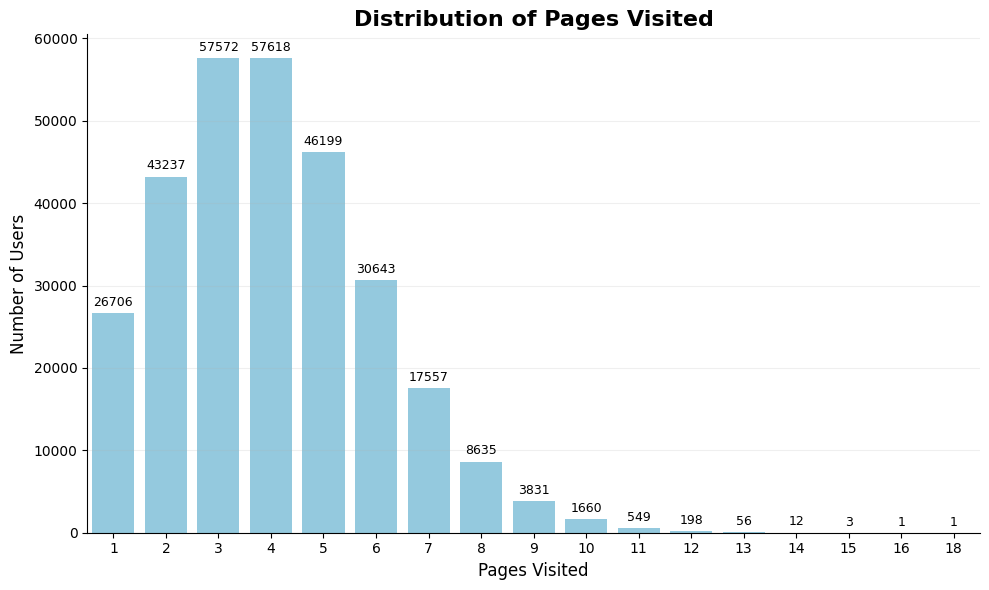

In [15]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    x=df['pages_visited'],
    color="skyblue"
)

plt.title("Distribution of Pages Visited", fontsize=16, fontweight="bold")
plt.xlabel("Pages Visited", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis="y", alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Pages Visited

Pages visited is a discrete numerical variable.

Most users visit a relatively small number of pages, while a smaller number of
users have higher page counts.

The higher values may represent users who explored more of the website and
should not automatically be considered invalid.

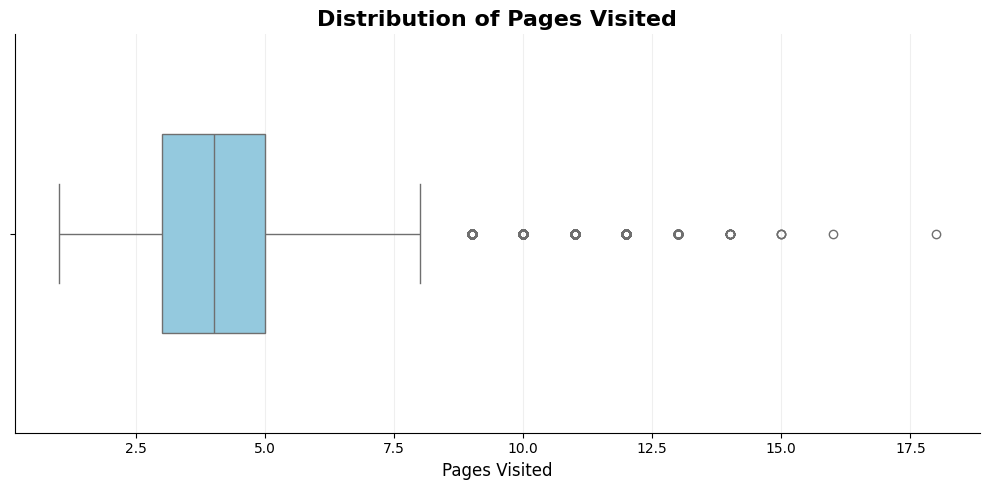

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['pages_visited'],
    color="skyblue",
    width=0.5
)

plt.title("Distribution of Pages Visited", fontsize=16, fontweight="bold")
plt.xlabel("Pages Visited", fontsize=12)

plt.grid(axis="x", alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

Most users visit around 3–5 pages, with a median of approximately 4 pages. The middle 50% of users visit approximately 3–5 pages. Higher values from around 9 pages onward are flagged as potential outliers, producing a long right tail.

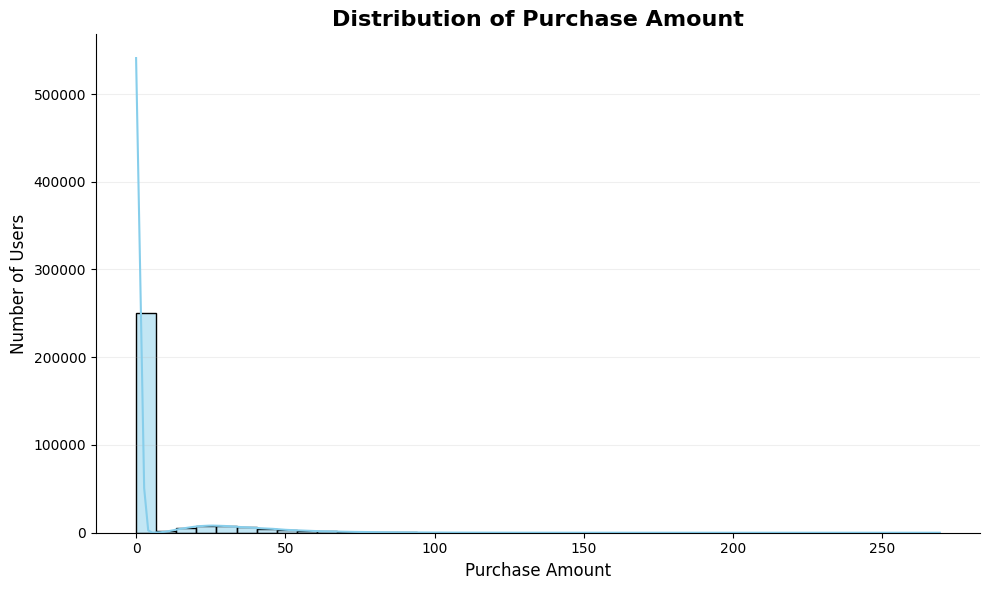

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['purchase_amount'],
    bins=40,
    kde=True,
    color='skyblue'
)

plt.title("Distribution of Purchase Amount", fontsize=16, fontweight='bold')
plt.xlabel("Purchase Amount", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

#### Purchase Amount

Purchase amount is strongly right-skewed because a large proportion of users
have no purchase amount, while users who make purchases can have substantially
higher values.

For understanding purchasing behavior, the distribution of positive purchase
amounts is particularly useful because zero values represent non-purchases.

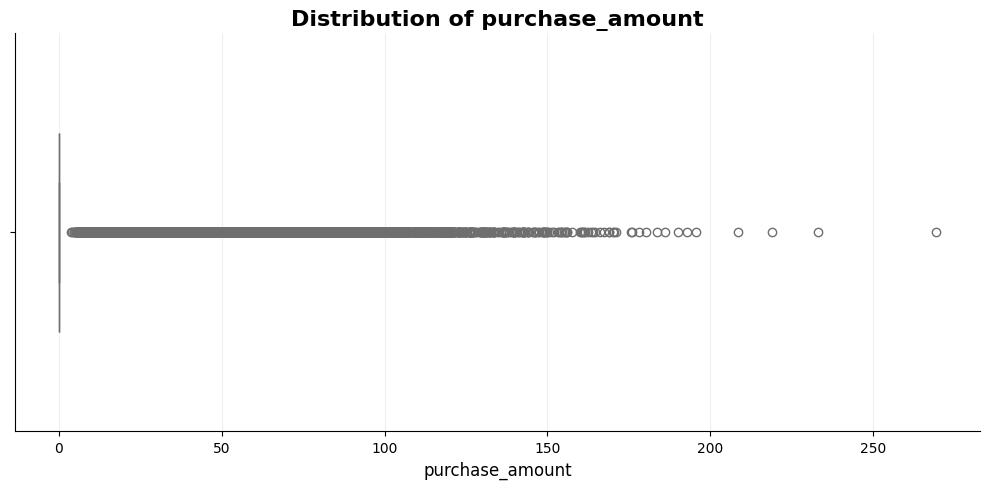

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['purchase_amount'],
    color="skyblue",
    width=0.5
)

plt.title("Distribution of purchase_amount", fontsize=16, fontweight="bold")
plt.xlabel("purchase_amount", fontsize=12)

plt.grid(axis="x", alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

Purchase amount is highly right-skewed, with a very large concentration of observations at zero. Positive purchase amounts are substantially less frequent and exhibit a long right tail extending to higher values. The box plot flags many positive values as potential outliers due to the highly skewed distribution; these values should not be removed without evidence that they are erroneous.

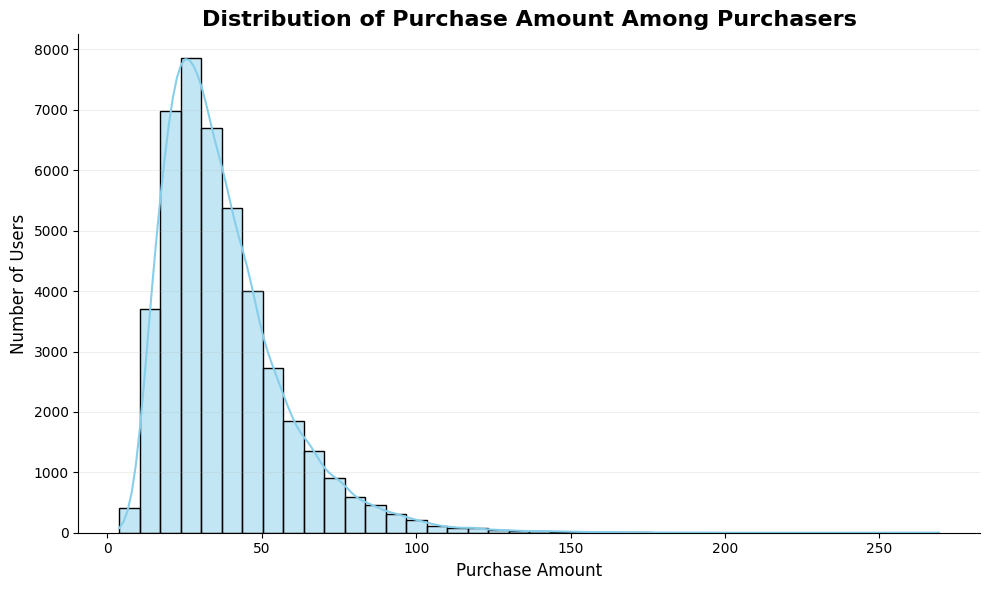

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df.loc[df['purchase_amount'] > 0, 'purchase_amount'],
    bins=40,
    kde=True,
    color='skyblue'
)

plt.title(
    "Distribution of Purchase Amount Among Purchasers",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Purchase Amount", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

Among users who made a purchase, purchase amounts are strongly positively skewed. Most purchases are concentrated around 20–40 units, with the highest frequency around 25–30 units. The frequency decreases as purchase amount increases, producing a long right tail extending to approximately 270 units.

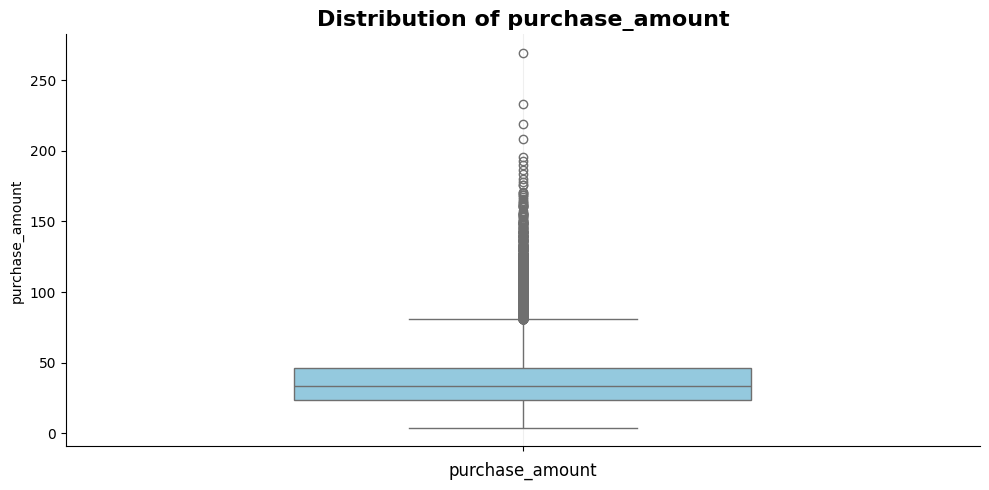

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    df.loc[df['purchase_amount'] > 0, 'purchase_amount'],
    color="skyblue",
    width=0.5
)

plt.title("Distribution of purchase_amount", fontsize=16, fontweight="bold")
plt.xlabel("purchase_amount", fontsize=12)

plt.grid(axis="x", alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

Among purchasers, the purchase amount has a strong positive skew. The median purchase amount is approximately 33, while the middle 50% of purchases lie between approximately 24 and 46. Values above approximately 80 are flagged as potential outliers, with some purchases extending to around 270. These observations may represent legitimate high-value purchases and should not be removed without further investigation.

### 6.2 Categorical Variables

Categorical variables are examined using frequency distributions to understand
the composition of the experimental population.

The variables examined are:

- `group`
- `landing_page`
- `gender`
- `location`
- `device_type`
- `converted`

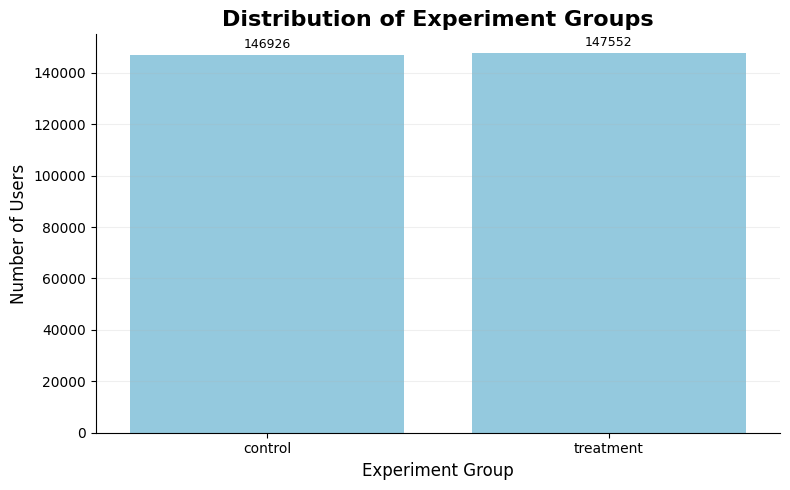

In [21]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['group'],
    color='skyblue'
)

plt.title("Distribution of Experiment Groups",
          fontsize=16, fontweight='bold')

plt.xlabel("Experiment Group", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Experiment Group

The Control and Treatment groups are approximately balanced in size, which is
desirable for comparing their conversion outcomes.

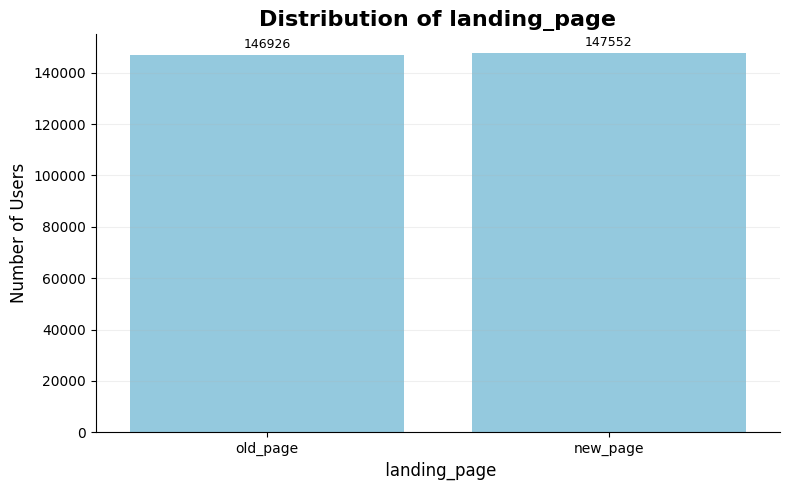

In [22]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['landing_page'],
    color='skyblue'
)

plt.title("Distribution of landing_page",
          fontsize=16, fontweight='bold')

plt.xlabel(" landing_page", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Landing Page

The landing page categories correspond directly to the experiment groups:

- Control → `old_page`
- Treatment → `new_page`

This confirms that the landing-page version is aligned with the experimental
assignment.

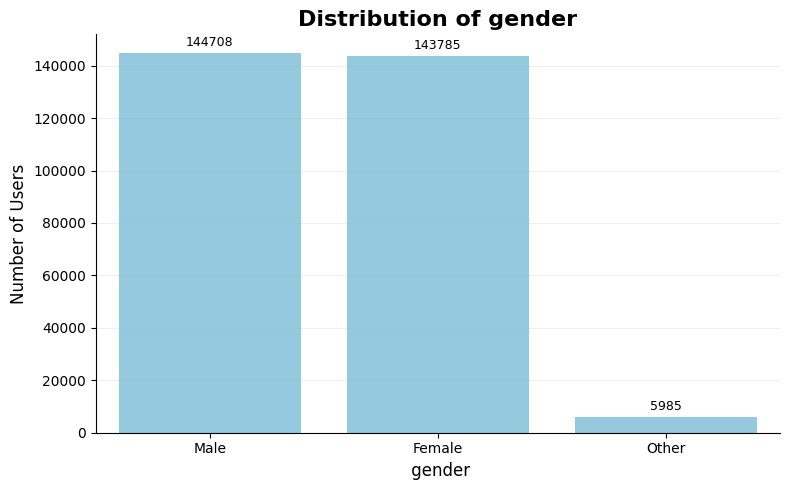

In [23]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['gender'],
    color='skyblue'
)

plt.title("Distribution of gender",
          fontsize=16, fontweight='bold')

plt.xlabel(" gender", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Gender

The dataset contains three gender categories: Male, Female, and Other.

Male and Female users make up the majority of the dataset, while the Other
category represents a smaller group.

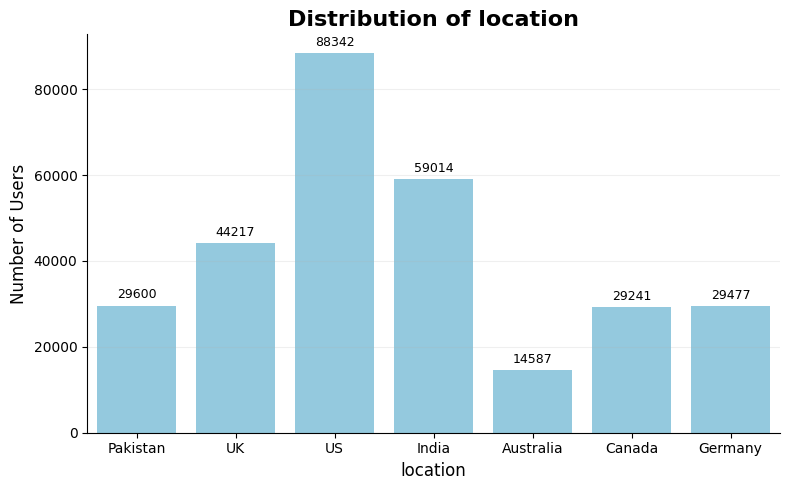

In [24]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['location'],
    color='skyblue'
)

plt.title("Distribution of location",
          fontsize=16, fontweight='bold')

plt.xlabel("location", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Location

Users come from multiple countries, with the United States representing the
largest group, followed by India and the United Kingdom.

This provides an opportunity to examine whether the treatment effect is
consistent across locations.

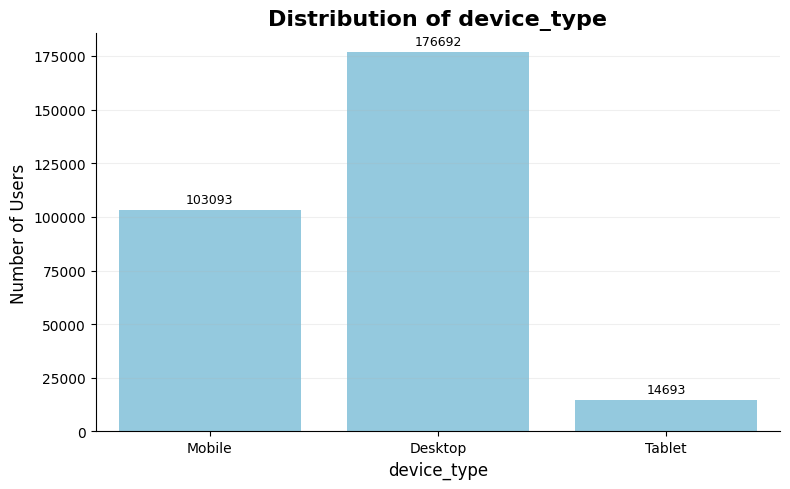

In [25]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['device_type'],
    color='skyblue'
)

plt.title("Distribution of device_type",
          fontsize=16, fontweight='bold')

plt.xlabel("device_type", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Device Type

Desktop users represent the largest device category, followed by Mobile and
Tablet users.

Device type can potentially influence user behavior, so it will also be
considered during segment analysis.

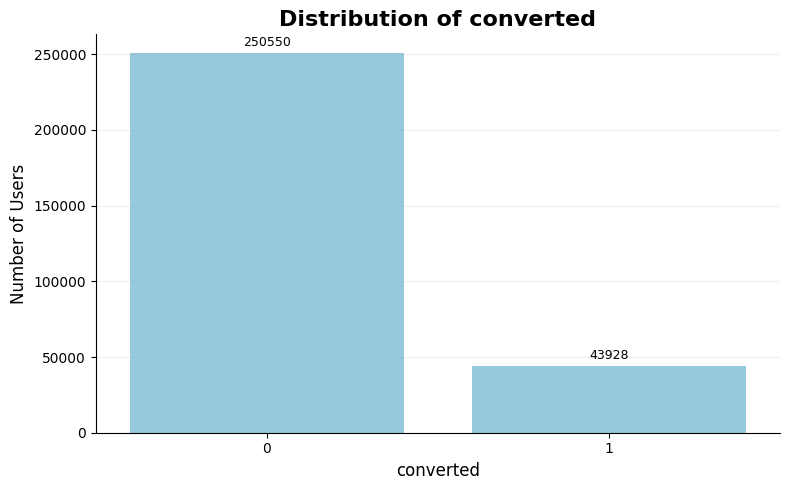

In [26]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['converted'],
    color='skyblue'
)

plt.title("Distribution of converted",
          fontsize=16, fontweight='bold')

plt.xlabel("converted", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### Conversion Outcome

The majority of users did not convert, while a smaller proportion completed
the desired action.

The overall conversion rate is approximately **14.92%**.


The conversion outcome is imbalanced, with 250,550 users (85.08%) not converting and 43,928 users (14.92%) converting. The overall conversion rate is approximately 14.92%.

## 6.3 EDA Summary

The exploratory analysis provides an initial understanding of the dataset.

Key observations:

- The Control and Treatment groups are approximately balanced.
- The numerical variables show varying degrees of skewness.
- Several numerical variables contain extreme but potentially valid
  observations.
- The majority of users do not convert.
- Users are distributed across multiple genders, locations, and device types.
- The landing-page assignment is aligned with the experiment groups.

These observations describe the dataset but do not determine whether the
Treatment landing page improves conversion. Statistical testing is required
to evaluate the treatment effect.

## 6.4 Bivariate Analysis

Bivariate analysis examines the relationship between two variables.

The primary comparison is:

> **Experiment Group × Conversion**

Additional comparisons are used to understand whether Treatment and Control
differ in user behavior such as session duration, pages visited, and purchase
amount.

In [27]:
total_users = len(df['group'])
total_users

294478

In [28]:
df['converted'].value_counts()

converted
0    250550
1     43928
Name: count, dtype: int64

In [29]:
no_of_converted_users = (df['converted'] == 1).sum()
no_of_converted_users

np.int64(43928)

In [30]:
no_of_not_converted_users = (df['converted'] == 0).sum()
no_of_not_converted_users

np.int64(250550)

In [31]:
Conversion_Rate = (no_of_converted_users/total_users)*100
print(Conversion_Rate)

14.917243393394413


In [32]:
Non_Conversion_Rate = (no_of_not_converted_users/total_users)*100
print(Non_Conversion_Rate)

85.08275660660559


In [33]:
df['group'].value_counts()

group
treatment    147552
control      146926
Name: count, dtype: int64

In [34]:
control_conversions = ((df['group'] == 'control') & (df['converted'] == 1)).sum()

In [35]:
control_conversion_rate = (control_conversions/146926)*100
print(f"The Control Conversion Rate  = {control_conversion_rate}")

The Control Conversion Rate  = 11.872643371493133


In [36]:
treatment_conversions = ((df['group'] == 'treatment') & (df['converted'] == 1)).sum()

In [37]:
treatment_conversion_rate = (treatment_conversions/147552)*100
print(f"The Treatment Conversion Rate  = {treatment_conversion_rate}")

The Treatment Conversion Rate  = 17.94892648015615


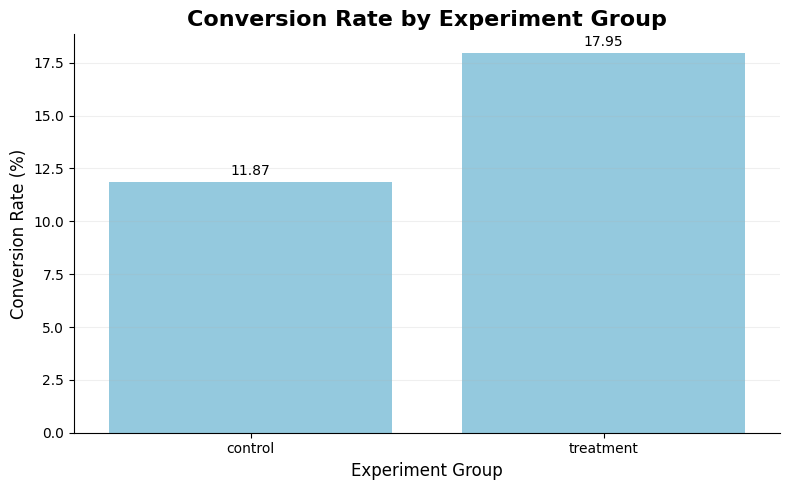

In [38]:
conversion_rates = {"control":control_conversion_rate,
                    "treatment":treatment_conversion_rate
                    }


plt.figure(figsize=(8, 5))

ax = sns.barplot(x=list(conversion_rates.keys()), 
      y=list(conversion_rates.values()),
      color = "skyblue"
)
plt.title("Conversion Rate by Experiment Group",
          fontsize=16, fontweight='bold')

plt.xlabel("Experiment Group", fontsize=12)
plt.ylabel("Conversion Rate (%)", fontsize=12)

plt.grid(axis ='y', alpha=0.2)
sns.despine()


for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)


plt.tight_layout()
plt.show()


#### Conversion Rate Comparison

The Control group has an observed conversion rate of approximately **11.87%**,
while the Treatment group has an observed conversion rate of approximately
**17.95%**.

This represents an observed absolute difference of approximately **6.08
percentage points**.

At this stage, this is a descriptive observation. Statistical hypothesis
testing is required to determine whether the observed difference is
statistically significant.

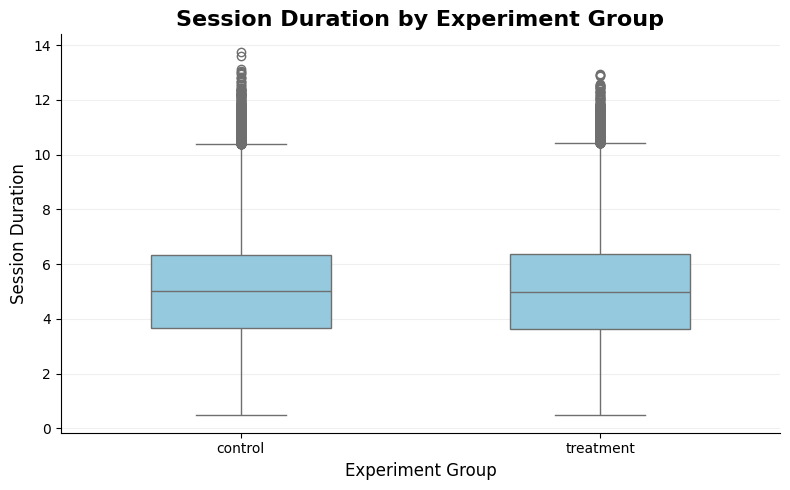

In [39]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='group', y='session_duration', 
            data=df, color='skyblue', width=0.5
            )

plt.title(
    "Session Duration by Experiment Group",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Experiment Group", fontsize=12)
plt.ylabel("Session Duration", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

Session duration shows a very similar distribution across the control and treatment groups. Both groups have a median session duration of approximately 5 units and comparable interquartile ranges. Both groups also contain several high-duration observations flagged as potential outliers.

### Experiment Group vs Pages Visited

We compare the number of pages visited between the Control and Treatment
groups to examine whether the landing-page versions are associated with
different browsing behavior.

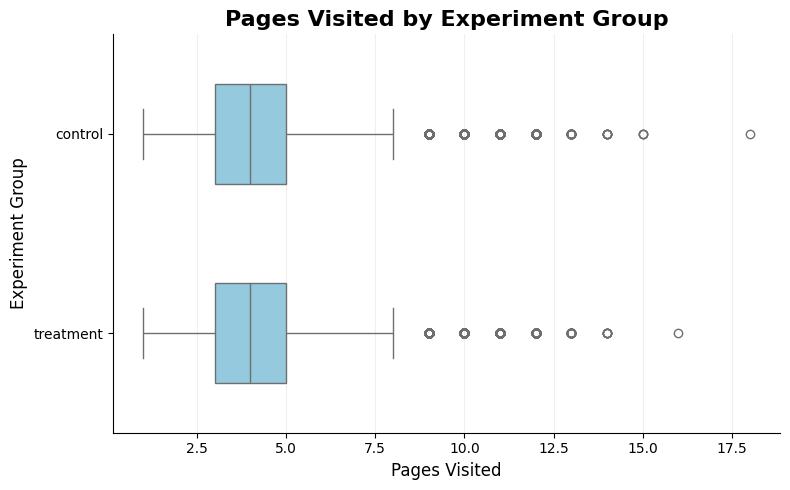

In [40]:
plt.figure(figsize=(8, 5))
sns.boxplot(y='group', x='pages_visited', 
            data=df, color='skyblue', width=0.5
            )

plt.title(
    "Pages Visited by Experiment Group",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Pages Visited", fontsize=12)
plt.ylabel("Experiment Group", fontsize=12)
plt.grid(axis='x', alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

#### Observation

The distributions of pages visited appear broadly similar between the two
experiment groups.

No strong visual difference is evident from the distribution alone.

### Experiment Group vs Purchase Amount

We compare purchase amounts between the Control and Treatment groups to
explore whether purchasing behavior differs between the two landing-page
versions.

Because non-purchasing users have a purchase amount of zero, the distribution
of positive purchase amounts is examined separately when evaluating purchase
size.

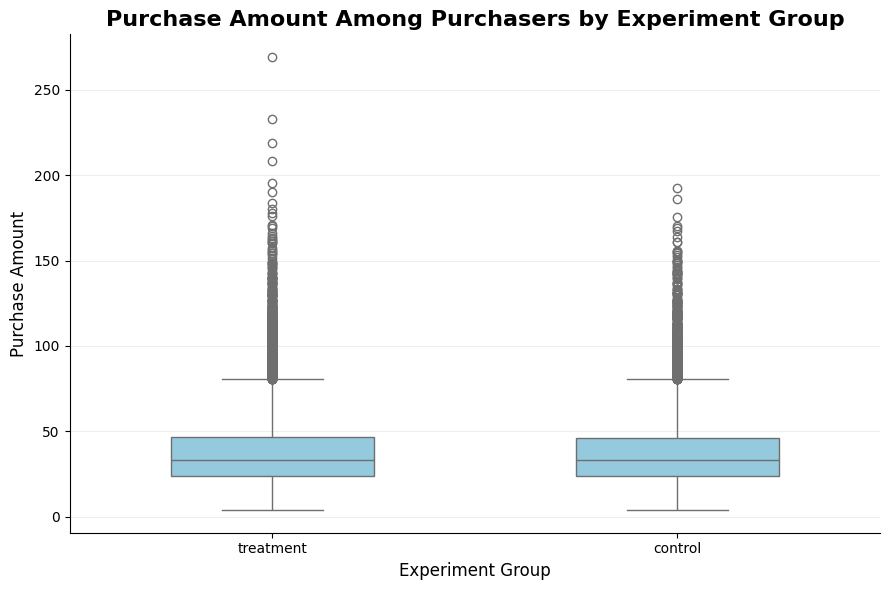

In [41]:
purchasers = df[df['purchase_amount'] > 0]

plt.figure(figsize=(9, 6))

sns.boxplot(
    x='group',
    y='purchase_amount',
    data=purchasers,
    color='skyblue',
    width=0.5
)

plt.title(
    "Purchase Amount Among Purchasers by Experiment Group",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Experiment Group", fontsize=12)
plt.ylabel("Purchase Amount", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

plt.tight_layout()
plt.show()

#### Observation

The purchase amount distributions show broadly similar patterns between the
Control and Treatment groups, although some extreme values are present.

The visual comparison alone is not sufficient to conclude that one group has
higher purchasing value.

### Conversion Rate by Gender

We compare conversion rates across gender categories to understand whether
conversion behavior differs across these user segments.

The comparison is descriptive and does not determine whether gender modifies
the treatment effect.

In [42]:
male_conversions = ((df['group'] == 'control') & (df['gender'] == "Male")).sum()

In [43]:
male_conversions = ((df['gender'] == 'Male') & (df['converted'] == 1)).sum()
female_conversions = ((df['gender'] == 'Female') & (df['converted'] == 1)).sum()
other_conversions = ((df['gender'] == 'Other') & (df['converted'] == 1)).sum()


male_conversion_rate = (male_conversions/144708)*100
female_conversion_rate = (female_conversions/143785)*100
other_conversion_rate = (other_conversions/5985)*100


print(f"Male Conversion Rate = {male_conversion_rate}")
print(f"Female Conversion Rate = {female_conversion_rate}")
print(f"Other Conversion Rate = {other_conversion_rate}")

Male Conversion Rate = 14.972219918732895
Female Conversion Rate = 14.84577668046041
Other Conversion Rate = 15.304928989139515


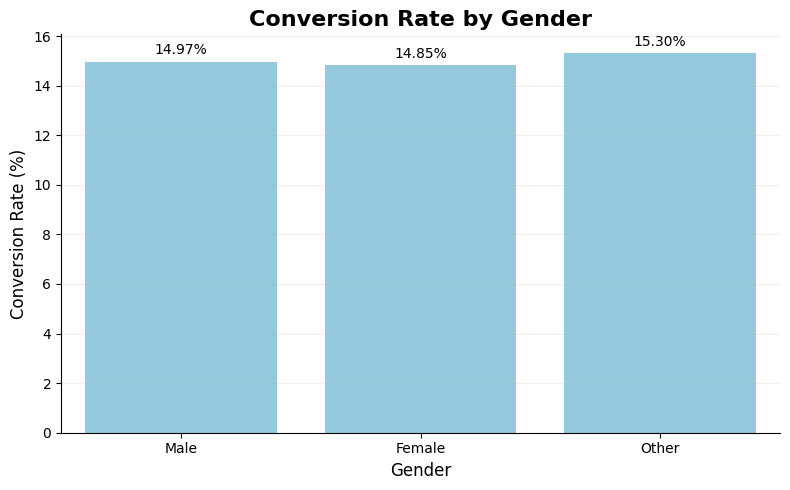

In [44]:
gender_rates = {
    'Male': male_conversion_rate,
    'Female': female_conversion_rate,
    'Other': other_conversion_rate
}

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=list(gender_rates.keys()),
    y=list(gender_rates.values()),
    color='skyblue'
)

plt.title(
    "Conversion Rate by Gender",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Gender", fontsize=12)
plt.ylabel("Conversion Rate (%)", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

#### Observation

The conversion rates are broadly similar across the gender categories.

The differences observed here are descriptive and require statistical testing
to determine whether the Treatment effect differs significantly by gender.

### Conversion Rate by Location

We compare conversion rates across different locations to examine whether
conversion behavior varies geographically.

This provides an initial descriptive view of conversion patterns across
locations.

In [45]:
US_conversions = ((df['location'] == 'US') & (df['converted'] == 1)).sum()
India_conversions = ((df['location'] == 'India') & (df['converted'] == 1)).sum()
UK_conversions = ((df['location'] == 'UK') & (df['converted'] == 1)).sum()
Pakistan_conversions = ((df['location'] == 'Pakistan') & (df['converted'] == 1)).sum()
Germany_conversions = ((df['location'] == 'Germany') & (df['converted'] == 1)).sum()
Canada_conversions = ((df['location'] == 'Canada') & (df['converted'] == 1)).sum()
Australia_conversions = ((df['location'] == 'Australia') & (df['converted'] == 1)).sum()


US_conversions_rate  = (US_conversions/88342)*100
India_conversions_rate = (India_conversions/59014)*100
UK_conversions_rate = (UK_conversions/44217)*100
Pakistan_conversions_rate  = (Pakistan_conversions/29600)*100
Germany_conversions_rate = (Germany_conversions/29477)*100
Canada_conversions_rate = (Canada_conversions/29241)*100
Australia_conversions_rate  = (Australia_conversions/14587)*100



print(f"US Conversion Rate = {US_conversions_rate}")
print(f"India Conversion Rate = {India_conversions_rate}")
print(f"UK Conversion Rate = {UK_conversions_rate}")
print(f"Pakistan Conversion Rate = {Pakistan_conversions_rate}")
print(f"Germany Conversion Rate = {Germany_conversions_rate}")
print(f"Canada Conversion Rate = {Canada_conversions_rate}")
print(f"Australia Conversion Rate = {Australia_conversions_rate}")


US Conversion Rate = 14.895519684861108
India Conversion Rate = 15.02016470667977
UK Conversion Rate = 14.919601058416445
Pakistan Conversion Rate = 14.89527027027027
Germany Conversion Rate = 14.645316687586933
Canada Conversion Rate = 15.06104442392531
Australia Conversion Rate = 14.93110303695071


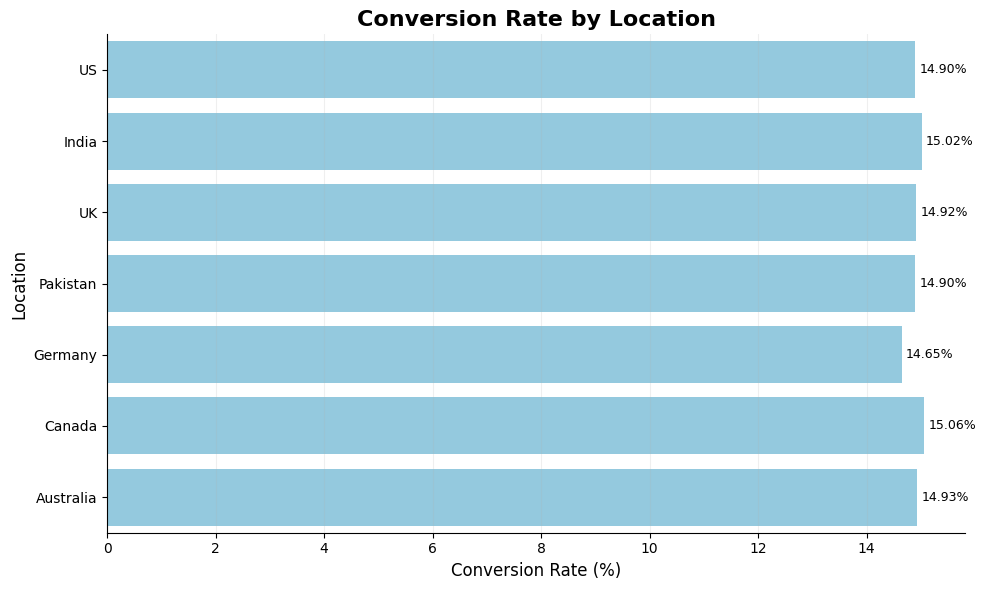

In [46]:
location_rates = {
    'US': US_conversions_rate,
    'India': India_conversions_rate,
    'UK': UK_conversions_rate,
    'Pakistan': Pakistan_conversions_rate,
    'Germany': Germany_conversions_rate,
    'Canada': Canada_conversions_rate,
    'Australia': Australia_conversions_rate
}

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=list(location_rates.values()),
    y=list(location_rates.keys()),
    color='skyblue'
)

plt.title(
    "Conversion Rate by Location",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Conversion Rate (%)", fontsize=12)
plt.ylabel("Location", fontsize=12)

plt.grid(axis='x', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=9)


plt.tight_layout()
plt.show()

#### Observation

Conversion rates are broadly similar across the locations in the dataset.

Although small differences are visible, descriptive rates alone cannot
establish whether the Treatment effect differs significantly by location.

### Conversion Rate by Device Type

We compare conversion rates across device types to examine whether users
accessing the website through different devices show different conversion
behavior.

In [47]:
desktop_conversions = ((df['device_type'] == 'Desktop') & (df['converted'] == 1)).sum()
mobile_conversions = ((df['device_type'] == 'Mobile') & (df['converted'] == 1)).sum()
tablet_conversions = ((df['device_type'] == 'Tablet') & (df['converted'] == 1)).sum()


desktop_conversion_rate = (desktop_conversions/176692)*100
mobile_conversion_rate = (mobile_conversions/103093)*100
tablet_conversion_rate = (tablet_conversions/14693)*100


print(f"Desktop Conversion Rate = {desktop_conversion_rate}")
print(f"Mobile Conversion Rate = {mobile_conversion_rate}")
print(f"Tablet Conversion Rate = {tablet_conversion_rate}")

Desktop Conversion Rate = 15.014262105811243
Mobile Conversion Rate = 14.749789025443047
Tablet Conversion Rate = 14.925474715851086


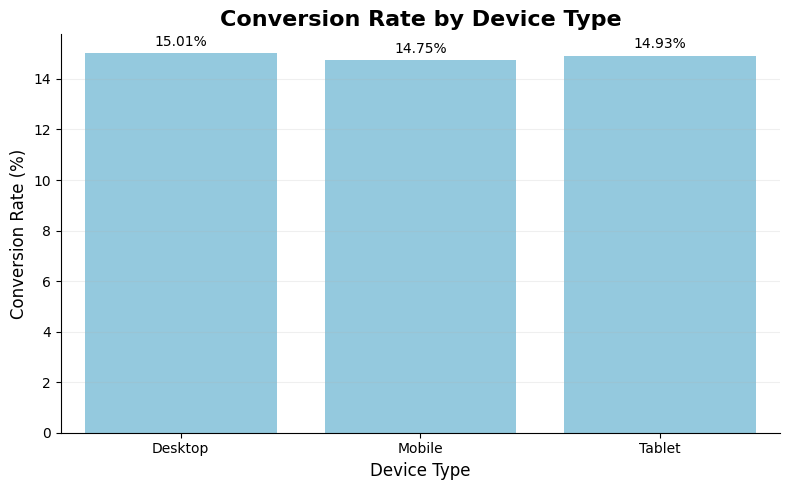

In [48]:
device_rates = {
    'Desktop': desktop_conversion_rate,
    'Mobile': mobile_conversion_rate,
    'Tablet': tablet_conversion_rate
}

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=list(device_rates.keys()),
    y=list(device_rates.values()),
    color='skyblue'
)

plt.title(
    "Conversion Rate by Device Type",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Device Type", fontsize=12)
plt.ylabel("Conversion Rate (%)", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

#### Observation

Conversion rates are broadly similar across Desktop, Mobile, and Tablet users.

The observed differences are descriptive and do not by themselves establish
whether device type modifies the Treatment effect.

## 6.5 EDA Summary

The exploratory analysis provides the following observations:

- Treatment has a higher observed conversion rate than Control.
- The observed overall difference in conversion is approximately **6.08
  percentage points**.
- Session duration and pages visited show broadly similar distributions
  between the experiment groups.
- Positive purchase amounts show broadly similar distributions.
- Conversion rates are broadly similar across gender, location, and device
  segments.
- These segment-level comparisons are descriptive and do not establish
  whether the Treatment effect differs between segments.

The most important observation is the difference in conversion rates between
the Control and Treatment groups.

Formal statistical testing is required to determine whether this observed
difference is statistically significant and whether the Treatment effect
differs across user segments.

## 7. Overall A/B Test

The exploratory analysis showed a difference in conversion rates between the
Control and Treatment groups.

We now perform a formal statistical test to determine whether this observed
difference is statistically significant.

A **two-proportion z-test** is used because the primary outcome,
`converted`, is binary and we are comparing conversion proportions between
two independent groups.

### 7.1 Hypothesis Testing

We test whether the true conversion rates of the Control and Treatment groups
are different.

#### Null Hypothesis ($H_0$)

$$
p_T = p_C
$$

There is no difference in the true conversion rates between Treatment and
Control.

#### Alternative Hypothesis ($H_a$)

$$
p_T \neq p_C
$$

There is a difference in the true conversion rates between Treatment and
Control.

We use a two-sided test with:

$$
\alpha = 0.05
$$

### 7.2 Observed Conversion Rates

Before performing the hypothesis test, we calculate the observed conversion
rate for each experiment group.

$$
\hat{p} = \frac{x}{n}
$$

where:

- $x$ = number of conversions
- $n$ = total number of users in the group

For this experiment:

- $n_T = 147,552$
- $x_T = 26,484$
- $n_C = 146,926$
- $x_C = 17,444$

In [49]:
control_n = 146926
control_x = 17444

treatment_n = 147552
treatment_x = 26484

In [50]:
control_rate = control_x / control_n
treatment_rate = treatment_x / treatment_n

In [51]:
print(control_rate)

0.11872643371493133


In [52]:
print(treatment_rate)

0.1794892648015615


#### Observed Results

- **Control conversion rate:** 11.87%
- **Treatment conversion rate:** 17.95%

### 7.3 Observed Difference in Conversion Rates

The observed treatment effect is calculated as:

$$
\hat{p}_T-\hat{p}_C
$$

For this experiment:

$$
17.95\%-11.87\% \approx 6.08\text{ percentage points}
$$

This is the observed difference in conversion rates. Statistical testing is
required to determine whether this difference is unlikely to be explained by
sampling variation alone.

### 7.4 Pooled Proportion

For the hypothesis test, the null hypothesis assumes that the Control and
Treatment groups have the same true conversion rate.

Therefore, we calculate a pooled conversion proportion:

$$
\hat{p} =
\frac{x_T+x_C}{n_T+n_C}
$$

where:

- $x_T$ = Treatment conversions
- $x_C$ = Control conversions
- $n_T$ = Treatment sample size
- $n_C$ = Control sample size

The pooled proportion is used to calculate the standard error under the null
hypothesis.

In [53]:
pooled_rate = (control_x + treatment_x) / (control_n + treatment_n)

In [54]:
pooled_rate*100

14.917243393394413

### 7.5 Standard Error

The standard error for the two-proportion z-test is:

$$
SE =
\sqrt{
\hat{p}(1-\hat{p})
\left(
\frac{1}{n_T}+\frac{1}{n_C}
\right)
}
$$

The pooled proportion is used here because the hypothesis test assumes that
the two groups have the same underlying conversion rate under $H_0$.

### 7.6 Z-Statistic

The general z-statistic is:

$$
z=\frac{X-\mu}{SE}
$$

For this two-proportion test:

$$
z=
\frac{(\hat{p}_T-\hat{p}_C)-0}{SE}
$$

Therefore:

$$
z=
\frac{\hat{p}_T-\hat{p}_C}{SE}
$$

In [55]:
pooled_rate = (treatment_conversions + control_conversions) / (
    treatment_n + control_n
)

se = np.sqrt(
    pooled_rate * (1 - pooled_rate) *
    (1 / treatment_n + 1 / control_n)
)

z_stat = (treatment_rate - control_rate) / se

z_stat

np.float64(46.277339891305736)

In [56]:
print("Z-statistic:", z_stat)

Z-statistic: 46.277339891305736


The observed difference is approximately **46.28 standard errors away from
the null value of zero**.

### 7.7 P-Value

The p-value measures how unusual the observed result would be if the null
hypothesis were true.

For a two-sided test:

$$
p\text{-value}
=
2\left(1-\Phi(|z|)\right)
$$

The calculated p-value is extremely small and is effectively zero at normal
floating-point precision.

Since:

$$
p\text{-value}<0.05
$$

we reject the null hypothesis.

In [57]:
from scipy.stats import norm

p_value = 2 * norm.sf(abs(z_stat))

print("P-value:", p_value)

P-value: 0.0


### 7.8 Statistical Conclusion

There is strong statistical evidence that the Treatment and Control groups
have different conversion rates.

The Treatment group has a substantially higher observed conversion rate than
the Control group.

However, statistical significance alone does not describe the practical size
or uncertainty of the effect. We therefore calculate a confidence interval
and relative lift next.

## 8. Confidence Interval

The hypothesis test tells us whether there is statistical evidence of a
difference between the two groups.

A confidence interval helps us estimate the **range of plausible values for
the true difference in conversion rates**.

We calculate a 95% confidence interval for:

$$
p_T-p_C
$$

### 8.1 Point Estimate

The point estimate of the treatment effect is the observed difference between
the Treatment and Control conversion rates:

$$
\hat{p}_T-\hat{p}_C
$$

For this experiment:

$$
\boxed{6.08\text{ percentage points}}
$$

This is our single best sample-based estimate of the difference in conversion
rates.

### 8.2 Standard Error for the Confidence Interval

For the confidence interval, we use the individual sample proportions rather
than the pooled proportion:

$$
SE_{CI}=
\sqrt{
\frac{\hat{p}_T(1-\hat{p}_T)}{n_T}
+
\frac{\hat{p}_C(1-\hat{p}_C)}{n_C}
}
$$

This differs from the hypothesis-test standard error because the confidence
interval estimates the uncertainty around the observed treatment effect,
whereas the hypothesis test calculates variability under the null hypothesis.

### 8.4 Margin of Error

The margin of error is calculated as:

$$
ME=z^*\times SE_{CI}
$$

For this analysis:

$$
ME\approx0.00256
$$

In [58]:
difference = treatment_rate - control_rate

se_ci = np.sqrt(
    (treatment_rate * (1 - treatment_rate) / treatment_n)
    + (control_rate * (1 - control_rate) / control_n)
)

z_critical = 1.96

margin_of_error = z_critical * se_ci

lower_ci = difference - margin_of_error
upper_ci = difference + margin_of_error

print(f"CI Standard Error: {se_ci:.6f}")
print(f"Margin of Error: {margin_of_error:.6f}")
print(f"95% CI: ({lower_ci * 100:.2f}%, {upper_ci * 100:.2f}%)")

CI Standard Error: 0.001308
Margin of Error: 0.002563
95% CI: (5.82%, 6.33%)


### 8.5 95% Confidence Interval

The confidence interval is:

$$
CI=
\text{Point Estimate}\pm\text{Margin of Error}
$$

Therefore:

$$
CI =
0.060763 \pm 0.002563
$$

which gives approximately:

$$
\boxed{[0.0582,\ 0.0633]}
$$

or:

$$
\boxed{[5.82\%,\ 6.33\%]}
$$

### 8.6 Interpretation

The estimated difference in conversion rates is approximately **6.08
percentage points**.

The 95% confidence interval ranges from approximately **5.82 to 6.33
percentage points**.

Because zero is not contained within the interval, the confidence interval is
consistent with the hypothesis-test result that there is a statistically
significant difference between the Treatment and Control conversion rates.

The relatively narrow interval is also consistent with the large sample size
of the experiment.

## 9. Relative Lift

Relative lift measures the treatment improvement relative to the Control
group's conversion rate.

$$
\text{Relative Lift}
=
\frac{\hat{p}_T-\hat{p}_C}{\hat{p}_C}\times100
$$

For this experiment:

$$
\boxed{51.18\%}
$$

This means that the observed Treatment conversion rate was approximately
**51.18% higher relative to the Control conversion rate**.

Relative lift describes the magnitude of the observed improvement. It does
not by itself establish statistical significance.

In [59]:
relative_lift = (
    (treatment_rate - control_rate)
    / control_rate
) * 100

print(f"Relative Lift: {relative_lift:.2f}%")

Relative Lift: 51.18%


## 10. Segment Analysis

The overall A/B test evaluates the treatment effect across all users.

We now examine conversion rates within different user segments to understand
whether the observed Treatment improvement is consistent across:

- Gender
- Location
- Device type

These comparisons are descriptive. Formal interaction tests will later be used
to determine whether the Treatment effect differs statistically across these
segments.

### 10.1 Conversion Rate by Gender

We compare the Control and Treatment conversion rates separately within each
gender category.

The treatment effect within each segment is calculated as:

$$
\text{Treatment Effect}
=
p_{Treatment}-p_{Control}
$$

In [60]:
gender_group_conversion = (
    df.groupby(['gender', 'group'])['converted']
      .mean()
      .reset_index()
)

gender_group_conversion

,gender,group,converted
0,Female,control,0.118258
1,Female,treatment,0.178432
2,Male,control,0.118870
3,Male,treatment,0.180569
4,Other,control,0.126565
5,Other,treatment,0.178878


In [61]:
gender_group_conversion['converted'] = (
    gender_group_conversion['converted'] * 100
)

gender_group_conversion

,gender,group,converted
0,Female,control,11.825810
1,Female,treatment,17.843186
2,Male,control,11.886991
3,Male,treatment,18.056938
4,Other,control,12.656514
5,Other,treatment,17.887789


### Treatment Effect by Gender

To investigate whether the treatment effect varies across gender segments,
we calculate the difference between the Treatment and Control conversion
rates within each gender:

$$
\text{Treatment Effect}_{gender}
=
p_{Treatment,gender}
-
p_{Control,gender}
$$

The results are:

| Gender | Control Conversion | Treatment Conversion | Treatment Effect |
|---|---:|---:|---:|
| Female | 11.83% | 17.84% | +6.02 pp |
| Male | 11.89% | 18.06% | +6.17 pp |
| Other | 12.66% | 17.89% | +5.23 pp |

The Treatment group has a higher observed conversion rate than the Control
group across all three gender segments.

The observed treatment effects are relatively similar for Female and Male
users, while the Other category shows a smaller difference.

However, these point estimates alone do not establish that gender changes
the treatment effect. Statistical uncertainty and the different sample sizes
across segments should be considered before concluding that treatment effects
differ by gender.

### 10.2 Conversion Rate by Location

We compare Control and Treatment conversion rates within each location.

This allows us to examine whether the observed improvement in conversion is
consistent across geographic segments.

In [62]:
location_group_conversion = (
    df.groupby(['location', 'group'])['converted']
      .mean()
      .reset_index()
)

location_group_conversion

,location,group,converted
0,Australia,control,0.118737
1,Australia,treatment,0.179814
2,Canada,control,0.122441
3,Canada,treatment,0.178713
4,Germany,control,0.115489
5,Germany,treatment,0.177669
6,India,control,0.118150
7,India,treatment,0.181975
8,Pakistan,control,0.117495
9,Pakistan,treatment,0.180089


In [63]:
location_group_conversion['converted'] = (
    location_group_conversion['converted'] * 100
)

location_group_conversion

,location,group,converted
0,Australia,control,11.873713
1,Australia,treatment,17.981375
2,Canada,control,12.244059
3,Canada,treatment,17.871294
4,Germany,control,11.548858
5,Germany,treatment,17.766878
6,India,control,11.814964
7,India,treatment,18.197463
8,Pakistan,control,11.749525
9,Pakistan,treatment,18.008873


#### Observation

The Treatment group has a higher observed conversion rate than the Control
group across all locations.

The observed treatment effects range from approximately **+5.63 to +6.38
percentage points** across the locations.

The differences are relatively close in magnitude, but formal in
teraction
testing is required to determine whether location statistically modifies the
Treatment effect.





















### 10.3 Conversion Rate by Device Type

We compare Control and Treatment conversion rates within each device category.

This helps determine whether the observed improvement is consistent across
Desktop, Mobile, and Tablet users.

In [64]:
device_group_conversion = (
    df.groupby(['device_type', 'group'])['converted']
      .mean()
      .reset_index()
)

device_group_conversion

,device_type,group,converted
0,Desktop,control,0.119495
1,Desktop,treatment,0.180826
2,Mobile,control,0.117436
3,Mobile,treatment,0.177132
4,Tablet,control,0.118471
5,Tablet,treatment,0.180084


In [65]:
device_group_conversion['converted'] = (
    device_group_conversion['converted'] * 100
)

device_group_conversion

,device_type,group,converted
0,Desktop,control,11.949501
1,Desktop,treatment,18.082564
2,Mobile,control,11.743557
3,Mobile,treatment,17.713229
4,Tablet,control,11.847116
5,Tablet,treatment,18.008446


#### Observation

The Treatment group has a higher observed conversion rate across all device
types.

The observed treatment effects are approximately:

- Desktop: **+6.13 percentage points**
- Mobile: **+5.97 percentage points**
- Tablet: **+6.16 percentage points**

The differences are small across device types. However, descriptive
comparisons alone cannot determine whether device type modifies the Treatment
effect.

### 10.4 Segment Analysis Summary

The Treatment group shows a higher observed conversion rate across all
examined gender, location, and device segments.

The treatment effects are relatively consistent across these segments.

However, these comparisons are based on observed conversion rates.
Statistical interaction tests are required to determine whether the Treatment
effect differs significantly between segments.

## 11. Treatment Effect Heterogeneity

The segment analysis showed that the Treatment group had higher observed
conversion rates across gender, location, and device segments.

However, similar-looking conversion rates do not necessarily mean that the
Treatment effect is statistically the same across segments.

To formally test whether the treatment effect differs between segments, we use
**interaction terms in logistic regression**.

An interaction term tests whether the effect of Treatment changes depending on
the value of another variable.

### 11.1 Treatment × Gender Interaction

We use a logistic regression model containing an interaction between
experiment group and gender.

The model tests whether the effect of the Treatment landing page differs
across gender categories.

The reference categories are automatically selected by the model. In this
analysis, Female is the reference gender category.

In [66]:
model_gender = smf.logit(
    "converted ~ C(group) * C(gender)",
    data=df
).fit()

model_gender.summary()

Optimization terminated successfully.
         Current function value: 0.417607
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               294478
Model:                          Logit   Df Residuals:                   294472
Method:                           MLE   Df Model:                            5
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                0.008698
Time:                        22:58:05   Log-Likelihood:            -1.2298e+05
converged:                       True   LL-Null:                   -1.2406e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
============================================================================================================
                                               coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
Intercept                                   -2.0090      0.012   -173.620      0.000      -2.032      -1.986
C(group)[T.treatment]                        0.4820      0.015     31.893      0.000       0.452       0.512
C(gender)[T.Male]                            0.0059      0.016      0.359      0.720      -0.026       0.038
C(gender)[T.Other]                           0.0774      0.057      1.368      0.171      -0.033       0.188
C(group)[T.treatment]:C(gender)[T.Male]      0.0087      0.021      0.406      0.684      -0.033       0.050
C(group)[T.treatment]:C(gender)[T.Other]    -0.0743      0.074     -0.999      0.318      -0.220       0.072
============================================================================================================
"""

### Interpretation

The interaction terms compare the Treatment effect for the other gender
categories against the reference category.

We use:

$$
\alpha = 0.05
$$

as the significance threshold.

The interaction p-values are:

- Treatment × Male: **p = 0.684**
- Treatment × Other: **p = 0.318**

Both p-values are greater than 0.05.

Therefore, there is **insufficient statistical evidence that gender modifies
the Treatment effect**.

### 11.2 Treatment × Location Interaction

We now test whether the Treatment effect differs across locations.

Australia is used as the reference location category.

In [67]:
model_location = smf.logit(
    "converted ~ C(group) * C(location)",
    data=df
).fit()

model_location.summary()

Optimization terminated successfully.
         Current function value: 0.417601
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               294478
Model:                          Logit   Df Residuals:                   294464
Method:                           MLE   Df Model:                           13
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                0.008712
Time:                        22:58:08   Log-Likelihood:            -1.2297e+05
converged:                       True   LL-Null:                   -1.2406e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
=================================================================================================================
                                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
Intercept                                        -2.0044      0.036    -55.342      0.000      -2.075      -1.933
C(group)[T.treatment]                             0.4868      0.047     10.285      0.000       0.394       0.580
C(location)[T.Canada]                             0.0349      0.044      0.791      0.429      -0.052       0.121
C(location)[T.Germany]                           -0.0314      0.044     -0.707      0.479      -0.118       0.056
C(location)[T.India]                             -0.0056      0.040     -0.139      0.889      -0.085       0.074
C(location)[T.Pakistan]                          -0.0119      0.044     -0.269      0.788      -0.099       0.075
C(location)[T.UK]                                 0.0170      0.042      0.409      0.683      -0.065       0.099
C(location)[T.US]                                -0.0026      0.039     -0.065      0.948      -0.079       0.074
C(group)[T.treatment]:C(location)[T.Canada]      -0.0424      0.058     -0.733      0.463      -0.156       0.071
C(group)[T.treatment]:C(location)[T.Germany]      0.0168      0.058      0.290      0.772      -0.097       0.131
C(group)[T.treatment]:C(location)[T.India]        0.0202      0.053      0.382      0.702      -0.083       0.124
C(group)[T.treatment]:C(location)[T.Pakistan]     0.0138      0.058      0.238      0.812      -0.100       0.127
C(group)[T.treatment]:C(location)[T.UK]          -0.0300      0.055     -0.550      0.582      -0.137       0.077
C(group)[T.treatment]:C(location)[T.US]          -0.0015      0.051     -0.029      0.977      -0.102       0.099
=================================================================================================================
"""

### Interpretation

The interaction terms compare the Treatment effect for each location against
the reference location, Australia.

The interaction p-values are:

- Canada: **p = 0.463**
- Germany: **p = 0.772**
- India: **p = 0.702**
- Pakistan: **p = 0.812**
- UK: **p = 0.582**
- US: **p = 0.977**

All interaction p-values are greater than 0.05.

Therefore, there is **insufficient statistical evidence that the Treatment
effect differs by location relative to Australia**.

### 11.3 Treatment × Device Interaction

We now test whether the Treatment effect differs across device types.

Desktop is used as the reference device category.

In [68]:
model_device = smf.logit(
    "converted ~ C(group) * C(device_type)",
    data=df
).fit()

model_device.summary()

Optimization terminated successfully.
         Current function value: 0.417604
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               294478
Model:                          Logit   Df Residuals:                   294472
Method:                           MLE   Df Model:                            5
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                0.008703
Time:                        22:58:10   Log-Likelihood:            -1.2298e+05
converged:                       True   LL-Null:                   -1.2406e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
==================================================================================================================
                                                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                         -1.9972      0.010   -192.613      0.000      -2.018      -1.977
C(group)[T.treatment]                              0.4865      0.014     35.864      0.000       0.460       0.513
C(device_type)[T.Mobile]                          -0.0197      0.017     -1.146      0.252      -0.053       0.014
C(device_type)[T.Tablet]                          -0.0098      0.038     -0.260      0.795      -0.083       0.064
C(group)[T.treatment]:C(device_type)[T.Mobile]    -0.0054      0.022     -0.241      0.810      -0.049       0.039
C(group)[T.treatment]:C(device_type)[T.Tablet]     0.0048      0.049      0.097      0.923      -0.091       0.101
==================================================================================================================
"""

### Interpretation

The interaction terms compare the Treatment effect for Mobile and Tablet
users against the reference category, Desktop.

The interaction p-values are:

- Treatment × Mobile: **p = 0.810**
- Treatment × Tablet: **p = 0.923**

Both p-values are greater than 0.05.

Therefore, there is **insufficient statistical evidence that device type
modifies the Treatment effect relative to Desktop**.

### 11.4 Overall Conclusion

The Treatment group showed higher observed conversion rates across gender,
location, and device segments.

However, the interaction analyses found insufficient statistical evidence
that the Treatment effect differs systematically across these segments.

Therefore, the observed improvement appears broadly consistent across the
examined user segments, although the absence of significant interaction does
not prove that the treatment effect is identical for every segment.

## 12. Adjusted Logistic Regression

The overall A/B test showed a significant difference in conversion between
the Control and Treatment groups.

We now use logistic regression to estimate the Treatment effect while
adjusting for other user characteristics.

Since the target variable `converted` is binary, logistic regression is
appropriate for this analysis.

The model includes:
- Experiment group
- Gender
- Location
- Device type
- Age
- Session duration
- Pages visited

The main coefficient of interest is the Treatment coefficient.

In [69]:
model_full = smf.logit(
    "converted ~ C(group) + C(gender) + C(location) + C(device_type) + age + session_duration + pages_visited",
    data=df
).fit()

model_full.summary()

Optimization terminated successfully.
         Current function value: 0.417586
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               294478
Model:                          Logit   Df Residuals:                   294463
Method:                           MLE   Df Model:                           14
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                0.008748
Time:                        22:58:14   Log-Likelihood:            -1.2297e+05
converged:                       True   LL-Null:                   -1.2406e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -1.9630      0.035    -55.836      0.000      -2.032      -1.894
C(group)[T.treatment]        0.4848      0.011     46.003      0.000       0.464       0.506
C(gender)[T.Male]            0.0110      0.010      1.044      0.296      -0.010       0.032
C(gender)[T.Other]           0.0341      0.037      0.928      0.354      -0.038       0.106
C(location)[T.Canada]        0.0104      0.029      0.364      0.716      -0.046       0.066
C(location)[T.Germany]      -0.0214      0.029     -0.750      0.453      -0.077       0.035
C(location)[T.India]         0.0063      0.026      0.240      0.810      -0.045       0.057
C(location)[T.Pakistan]     -0.0036      0.028     -0.127      0.899      -0.059       0.052
C(location)[T.UK]           -0.0004      0.027     -0.016      0.987      -0.053       0.052
C(location)[T.US]           -0.0034      0.025     -0.133      0.894      -0.053       0.046
C(device_type)[T.Mobile]    -0.0229      0.011     -2.069      0.039      -0.045      -0.001
C(device_type)[T.Tablet]    -0.0073      0.024     -0.300      0.764      -0.055       0.040
age                         -0.0014      0.001     -2.505      0.012      -0.003      -0.000
session_duration            -0.0004      0.003     -0.136      0.892      -0.005       0.005
pages_visited                0.0021      0.003      0.804      0.422      -0.003       0.007
============================================================================================
"""

### 12.1 Treatment Effect

The coefficient for the Treatment group is approximately **0.4848** with a
very small p-value.

This indicates that, after adjusting for the other variables included in
the model, the Treatment group has significantly higher estimated log-odds
of conversion than the Control group.

However, logistic regression coefficients are expressed in log-odds, so the
coefficient itself is not the easiest quantity to interpret directly.

Therefore, we convert the Treatment coefficient into an **odds ratio**.

In [70]:
treatment_coef = model_full.params['C(group)[T.treatment]']

odds_ratio = np.exp(treatment_coef)

odds_ratio

np.float64(1.6239263363475163)

### 12.2 Adjusted Odds Ratio

The adjusted odds ratio for Treatment is approximately **1.624**.

This means that, holding the other variables in the model constant, the
estimated odds of conversion under Treatment are approximately **1.62 times**
the odds under Control.

In percentage terms:

\[
(1.624 - 1) \times 100 \approx 62.4\%
\]

Therefore, the Treatment group has approximately **62.4% higher estimated
odds of conversion** after adjustment.

This should not be interpreted as a 62.4% increase in conversion probability.
Odds and probability are different quantities.

### 12.3 Confidence Interval for the Adjusted Odds Ratio

We can calculate a 95% confidence interval for the Treatment odds ratio by
exponentiating the confidence interval of the Treatment coefficient.

In [71]:
model_full = smf.logit(
    "converted ~ C(group) + C(gender) + C(location) + C(device_type) + age + session_duration + pages_visited",
    data=df
).fit()

model_full.summary()

Optimization terminated successfully.
         Current function value: 0.417586
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               294478
Model:                          Logit   Df Residuals:                   294463
Method:                           MLE   Df Model:                           14
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                0.008748
Time:                        22:58:18   Log-Likelihood:            -1.2297e+05
converged:                       True   LL-Null:                   -1.2406e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -1.9630      0.035    -55.836      0.000      -2.032      -1.894
C(group)[T.treatment]        0.4848      0.011     46.003      0.000       0.464       0.506
C(gender)[T.Male]            0.0110      0.010      1.044      0.296      -0.010       0.032
C(gender)[T.Other]           0.0341      0.037      0.928      0.354      -0.038       0.106
C(location)[T.Canada]        0.0104      0.029      0.364      0.716      -0.046       0.066
C(location)[T.Germany]      -0.0214      0.029     -0.750      0.453      -0.077       0.035
C(location)[T.India]         0.0063      0.026      0.240      0.810      -0.045       0.057
C(location)[T.Pakistan]     -0.0036      0.028     -0.127      0.899      -0.059       0.052
C(location)[T.UK]           -0.0004      0.027     -0.016      0.987      -0.053       0.052
C(location)[T.US]           -0.0034      0.025     -0.133      0.894      -0.053       0.046
C(device_type)[T.Mobile]    -0.0229      0.011     -2.069      0.039      -0.045      -0.001
C(device_type)[T.Tablet]    -0.0073      0.024     -0.300      0.764      -0.055       0.040
age                         -0.0014      0.001     -2.505      0.012      -0.003      -0.000
session_duration            -0.0004      0.003     -0.136      0.892      -0.005       0.005
pages_visited                0.0021      0.003      0.804      0.422      -0.003       0.007
============================================================================================
"""

In [72]:
coef_ci = model_full.conf_int().loc['C(group)[T.treatment]']

or_ci = np.exp(coef_ci)

or_ci

0    1.590725
1    1.657820
Name: C(group)[T.treatment], dtype: float64

The 95% confidence interval for the adjusted odds ratio is approximately:

\[
[1.591,\ 1.658]
\]

Because the entire interval is above 1, the adjusted Treatment effect is
statistically distinguishable from an odds ratio of 1.

Overall, the adjusted logistic regression supports the conclusion from the
A/B test that the Treatment group has substantially higher conversion odds
than the Control group.

### 12.4 Adjusted Regression Summary

The adjusted logistic regression estimates an odds ratio of approximately
**1.624 (95% CI: 1.591–1.658)** for the Treatment group.

This means that after controlling for the demographic, device, and behavioral
variables included in the model, the Treatment group has approximately
**1.62 times the estimated odds of conversion** compared with Control.

The result is consistent with the earlier two-proportion A/B test.

## 13. Final Conclusion & Business Recommendation

The A/B test shows a substantial difference in conversion between the Control
and Treatment landing pages.

The Treatment landing page achieved a conversion rate of **17.95%**, compared
with **11.87%** for Control.

This corresponds to:

- **+6.08 percentage points** absolute improvement
- **51.18% relative lift**
- 95% confidence interval for the difference: **+5.82 to +6.33 percentage points**
- Adjusted odds ratio: **1.624**
- 95% CI for adjusted odds ratio: **1.591–1.658**

The hypothesis test also provided strong statistical evidence of a difference
between the two groups.

Segment-level analysis showed higher Treatment conversion across gender,
location, and device categories. However, the interaction analyses did not
provide sufficient statistical evidence that the Treatment effect differs
systematically across these segments.

The adjusted logistic regression produced a similar conclusion after
controlling for the other variables included in the model.

### 13.1 Business Recommendation

Based on the observed results, the Treatment landing page provides evidence
of a statistically significant and practically meaningful improvement in
conversion compared with the Control landing page.

If the original experiment used valid random assignment and the experimental
assumptions were satisfied, these results support considering a controlled
rollout of the Treatment landing page.

Before full deployment, the company should also consider:

- Implementation and maintenance costs
- Value generated by each additional conversion
- Stability of the treatment effect over time
- Whether the result remains consistent in production traffic
- Any technical or operational risks associated with deployment

The dataset does not contain sufficient information to calculate the actual
financial impact of deploying the Treatment page.

### 13.2 Causal Interpretation

The analysis is consistent with a positive causal effect of the new landing
page on conversion **if the experiment used valid random assignment and the
required experimental assumptions were satisfied**.

The dataset itself does not allow us to independently verify that random
assignment was properly implemented.

Therefore, the results should be interpreted as strong experimental evidence
under the stated assumptions rather than as an unconditional causal claim.

### 13.3 Limitations

1. **Randomization cannot be verified**

   The dataset does not provide enough information to independently confirm
   how users were assigned to Control and Treatment.

2. **Unobserved variables**

   Factors such as traffic source, previous user behavior, marketing
   campaigns, time of day, or seasonality may influence conversion but are
   not included in the dataset.

3. **Experiment duration**

   The available data does not establish whether the observed treatment effect
   remains stable over a longer period.

4. **Dataset representativeness**

   The dataset is a prepared dataset and may not perfectly represent the
   conditions of a real production experiment.

5. **Revenue impact**

   Conversion improvement does not directly tell us the financial impact.
   Information about revenue per conversion, customer lifetime value, and
   implementation cost would be required for a financial evaluation.

### 13.4 Final Summary

This project followed a complete A/B testing workflow:

**Business Problem → Experiment Audit → Data Cleaning → EDA → A/B Test →
Confidence Interval → Relative Lift → Segment Analysis → Interaction Testing →
Adjusted Logistic Regression → Business Interpretation**

The analysis found a substantial increase in observed conversion for the
Treatment landing page compared with Control.

The results were statistically significant, the estimated effect was
practically meaningful, and the treatment effect appeared broadly consistent
across the analyzed user segments.

The final business decision should combine these statistical findings with
production validation, implementation considerations, and financial impact.